# Lesson 1.4: Histograms, Shape and Skewness

Use the lesson's 20 exam scores to tally a histogram, compare mean and median, and measure skewness.

Part of *Statistics from Scratch*. Run each cell with **Shift + Enter**, top to bottom.

## The question

A teacher has 20 exam scores. The mean is 65.7 and the median 65.5, which sounds like an ordinary class. Before she trusts the average she wants to see the shape: are the scores balanced, or stretched out by a few very high ones?

If a package is missing on your computer, run the next cell once. In Google Colab everything is already installed.

In [ ]:
%pip install -q numpy scipy pandas statsmodels matplotlib

## Step 1: Mean versus median

The lesson's 20 exam scores. When the mean sits above the median, a tail is pulling it to the right, which hints at right skew.

In [1]:
import numpy as np  # Load NumPy, the library for lists of numbers, as np.
from scipy import stats  # Load SciPy's statistics tools; we need stats.skew in step 3.
import matplotlib.pyplot as plt  # Load Matplotlib's pyplot as plt, for the histogram in step 4.

scores = np.array([42, 48, 51, 55, 57, 58, 61, 62, 63, 65, 66, 67, 68, 70, 72, 73, 75, 79, 84, 98])  # Store the 20 exam scores in an array.

print(f'mean   = {scores.mean():.1f}')  # Print the mean, the balance point of the scores.
print(f'median = {np.median(scores):.1f}')  # Print the median. If the mean sits above the median, a right tail may be pulling it.

mean   = 65.7
median = 65.5


**What this means.** The mean is 65.7 and the median 65.5, only 0.2 apart. By this test the class is close to balanced, with at most a slight pull to the right. The histogram and a skewness number will show the shape more clearly.

## Step 2: Tally the bins

np.histogram counts how many scores fall in each bin. Bins of width 10 starting at 40 match the lesson. A bin includes its lower edge, and the counts must add up to 20.

In [2]:
edges = np.arange(40, 101, 10)  # Bin edges 40, 50, ... 100. The stop value 101 is not included, so 100 is the last edge. A width of 10 matches the lesson.
counts, _ = np.histogram(scores, bins=edges)  # Count the scores in each bin. A bin includes its lower edge. The underscore ignores the edges, which we already have.

for lo, c in zip(edges[:-1], counts):  # Walk through the bins together with their counts.
    print(f'{lo} to {lo + 9}: {c}')  # Print each bin as 'start to end: count'.
print('total =', counts.sum())  # Print the total. It must equal 20, otherwise some score fell outside the bins.

40 to 49: 2
50 to 59: 4
60 to 69: 7
70 to 79: 5
80 to 89: 1
90 to 99: 1
total = 20


**What this means.** The counts are 2, 4, 7, 5, 1 and 1, and they add up to 20, so every score is in a bin. The tallest bin is 60 to 69 with 7 students. The right side stretches further from the centre than the left: the top score (98) is about 33 above the median, while the lowest (42) is about 24 below.

## Step 3: A number for skewness

stats.skew measures lopsidedness. The default (bias=True) is the plain population formula. bias=False applies the small-sample correction that Excel and SPSS use, and that the lesson quotes (0.53). A positive value means a longer right tail, and mirroring the data flips the sign.

In [3]:
print(f'skew, default formula   = {stats.skew(scores):.3f}')  # The default stats.skew uses the plain population formula (bias=True).
print(f'skew, sample-corrected   = {stats.skew(scores, bias=False):.3f}')  # bias=False adds the small-sample correction used by Excel and SPSS, and quoted in the lesson.
mirror = 100 - scores  # Mirror the data by taking 100 minus each score. This turns a right tail into a left tail.
print(f'mirrored (left-skewed)   = {stats.skew(mirror, bias=False):.3f}')  # Print the skewness of the mirrored data, to see that the sign flips.

skew, default formula   = 0.486
skew, sample-corrected   = 0.527
mirrored (left-skewed)   = -0.527


**What this means.** Skewness is 0.486 with the plain formula and 0.527 with the small-sample correction (the figure the lesson quotes). Positive means a longer right tail. The mirrored data give -0.527, a left-skewed shape. As a rough guide, values between -0.5 and 0.5 are near symmetric, so 0.53 is a mild right skew.

## Step 4: Draw the histogram

The bars touch because the scores sit on one number line. The long tail on the right (84 and 98) is easy to see. The dashed line marks the mean and the solid line the median.

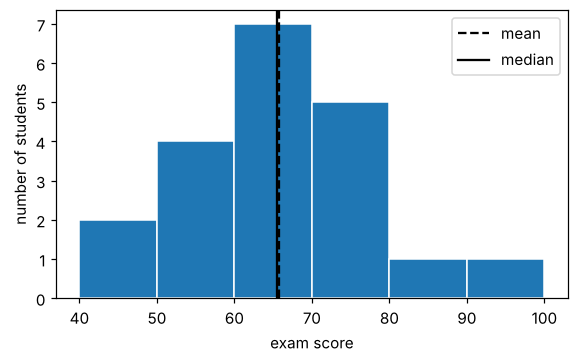

In [4]:
plt.figure(figsize=(6, 3.4))  # Open a new blank figure, 6 by 3.4 inches.
plt.hist(scores, bins=edges, edgecolor='white')  # Draw the histogram with our bin edges. The white edges make the bars easy to tell apart.
plt.axvline(scores.mean(), linestyle='--', color='black', label='mean')  # Add a dashed vertical line at the mean.
plt.axvline(np.median(scores), color='black', label='median')  # Add a solid vertical line at the median.
plt.xlabel('exam score')  # Label the horizontal axis with what the numbers are.
plt.ylabel('number of students')  # Label the vertical axis: each bar counts students.
plt.legend()  # Add a legend, so the reader knows which line is the mean and which is the median.
plt.show()  # Show the figure.

**What this means.** The bars touch because scores sit on one number line. The tallest bar is 60 to 69, and the bars thin out slowly toward the right (84 and 98), so the right tail is longer. The dashed mean line lies almost on top of the solid median line, which agrees that the skew is only mild.

## So, what is the answer?

The 20 scores are close to symmetric with a mild right tail: the mean (65.7) and median (65.5) are nearly equal, the skewness is +0.53 and the histogram stretches a little further toward the high scores (84 and 98). Mean and SD give a fair summary here. Caution: with only 20 scores the shape is uncertain, and a different bin width can change how the histogram looks.

## Now you try

A city planner records the commute time (in minutes) of 25 workers. Most commute under 40 minutes, but a few travel much longer. She wants to know whether to describe the typical commute with the mean or the median.

**Data:** commute = [12, 15, 18, 20, 22, 23, 25, 26, 27, 28, 30, 31, 33, 35, 36, 38, 40, 44, 47, 52, 58, 65, 75, 90, 110]

1. Find the mean and median of the commute times.
2. Count the commutes in 20-minute bins from 0 to 120.
3. Compute the sample-corrected skewness.
4. Name the shape and say which average you would report.

*Hint:* Use np.histogram with bins=np.arange(0, 121, 20) and stats.skew(data, bias=False). A mean above the median points to a right tail.

In [ ]:
# Your turn: write your code here


### Solution (try first, then peek)

In [ ]:
import numpy as np
from scipy import stats

commute = np.array([12, 15, 18, 20, 22, 23, 25, 26, 27, 28, 30, 31, 33, 35, 36, 38, 40, 44, 47, 52, 58, 65, 75, 90, 110])
print(f'n = {len(commute)}, mean = {commute.mean():.1f}, median = {np.median(commute):.1f}')
counts, _ = np.histogram(commute, bins=np.arange(0, 121, 20))
print('counts per 20-minute bin:', counts)
print(f'skewness (sample-corrected) = {stats.skew(commute, bias=False):.2f}')

n = 25, mean = 40.0, median = 33.0
counts per 20-minute bin: [ 3 13  5  2  1  1]
skewness (sample-corrected) = 1.51


**Answer.** The mean is 40.0 minutes but the median is 33.0, a gap of 7. The bin counts are 3, 13, 5, 2, 1, 1: 13 of 25 commutes fall in the 20 to 39 bin, with a long thin tail up to 110. Skewness is 1.51, clearly right-skewed. Report the median, 33 minutes, as the typical commute and mention the tail.

## The same question in R, SPSS and Stata

**R**

```r
x <- c(42, 48, 51, 55, 57, 58, 61, 62, 63, 65, 66, 67, 68, 70, 72, 73, 75, 79, 84, 98)  # Store the 20 exam scores in a vector.
mean(x); median(x)  # Two commands on one line, separated by a semicolon: the mean and then the median.
hist(x, breaks = seq(40, 100, by = 10), right = FALSE)  # Draw the histogram with bins from 40 to 100 in steps of 10. right = FALSE makes each bin include its lower edge, as in Python.
n <- length(x); m <- mean(x)  # Store n and the mean in two variables, to keep the next formula short.
g1 <- (sum((x - m)^3) / n) / (sum((x - m)^2) / n)^1.5  # Skewness g1: the average cubed deviation divided by the SD cubed. Cubing keeps the sign, so the tail direction shows.
g1  # Print g1.
g1 * sqrt(n * (n - 1)) / (n - 2)  # Multiply by sqrt(n(n - 1)) / (n - 2), the small-sample correction used by SPSS and Excel.
```

How to read it: R prints 65.7 and 65.5, a histogram with bars of height 2, 4, 7, 5, 1, 1, then g1 = 0.486 and the corrected value 0.527. A positive skewness means a tail to the right, here a mild one.

**SPSS** (Analyze > Descriptive Statistics > Frequencies > Statistics and Charts)

```
DATA LIST FREE / score.
BEGIN DATA
42  48  51  55  57  58  61  62  63  65  66  67  68  70  72  73  75  79  84  98
END DATA.
FREQUENCIES VARIABLES=score
  /FORMAT=NOTABLE
  /STATISTICS=MEAN MEDIAN SKEWNESS SESKEWNESS
  /HISTOGRAM.
```

How to read it: In the Statistics table read Mean 65.70, Median 65.50, Skewness 0.527 and Std. Error of Skewness 0.512. The skewness is only about one standard error above 0, so it is not clearly different from a symmetric shape. The histogram shows the same mild right tail.

**Stata**

```
clear
set obs 20
generate score = real(word("42  48  51  55  57  58  61  62  63  65  66  67  68  70  72  73  75  79  84  98", _n))
summarize score, detail
display r(skewness) * sqrt(r(N) * (r(N) - 1)) / (r(N) - 2)
histogram score, width(10) start(40) frequency
```

How to read it: summarize shows Mean 65.7, the 50% row 65.5 (the median) and Skewness .486. The display line applies the correction and prints about .527. The histogram has bars 10 wide from 40, with a slightly longer tail on the right.